# STA Session 7 — live Python demonstrations

Run the cells in order alongside the lecture notes. These examples use laboratory concentration, pump flow, and 3D-print yield; they are separate from this year's assignment.

Notation: the calculated values are z_obs and t_obs; the cutoffs set by alpha are z_crit and t_crit. The p-value is a tail area under H0, not the probability that H0 is true.

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm, t, binom, binomtest
from statsmodels.stats.proportion import proportion_confint

BLUE = "#174A73"
LIGHT_BLUE = "#6CA2C6"
ORANGE = "#D66B20"
INK = "#263645"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 11})

## Code 1 — Critical regions and p-values

Use the same observed value, t_obs = 2.4, under a t distribution with 15 degrees of freedom. Only the prespecified alternative changes. Orange marks the rejection region fixed by alpha; light blue marks the p-value area fixed by t_obs. Compare the right, left, and two-sided questions.

  greater: t_obs=2.40, t_crit=1.753, p=0.0149
     less: t_obs=2.40, t_crit=-1.753, p=0.9851
two-sided: t_obs=2.40, t_crit=2.131, p=0.0298


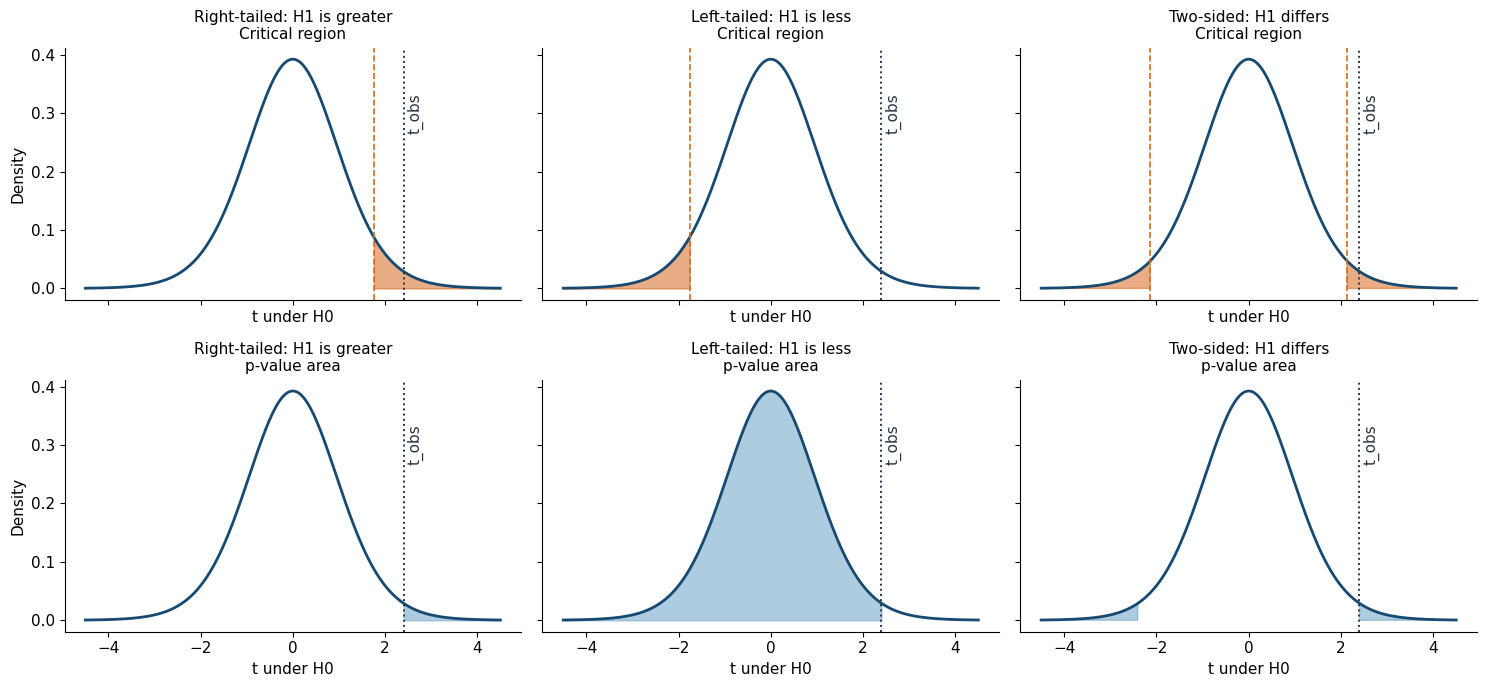

In [5]:
alpha, df, t_obs = 0.05, 15, 2.4
grid = np.linspace(-4.5, 4.5, 1200)
density = t.pdf(grid, df=df)

views = [
    ("Right-tailed: H1 is greater", "greater", t.ppf(1 - alpha, df), t.sf(t_obs, df)),
    ("Left-tailed: H1 is less", "less", t.ppf(alpha, df), t.cdf(t_obs, df)),
    ("Two-sided: H1 differs", "two-sided", t.ppf(1 - alpha / 2, df), 2 * t.sf(abs(t_obs), df)),
]
fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharex=True, sharey=True)

for column, (title, alternative, t_crit, p_value) in enumerate(views):
    if alternative == "greater":
        critical_region = grid >= t_crit
        p_region = grid >= t_obs
        cutoffs = [t_crit]
    elif alternative == "less":
        critical_region = grid <= t_crit
        p_region = grid <= t_obs
        cutoffs = [t_crit]
    else:
        critical_region = abs(grid) >= t_crit
        p_region = abs(grid) >= abs(t_obs)
        cutoffs = [-t_crit, t_crit]

    for row, region, color, label in [
        (0, critical_region, ORANGE, "Critical region"),
        (1, p_region, LIGHT_BLUE, "p-value area"),
    ]:
        ax = axes[row, column]
        ax.plot(grid, density, color=BLUE, lw=2)
        ax.fill_between(grid, density, where=region, color=color, alpha=0.55)
        ax.axvline(t_obs, color=INK, linestyle=":", lw=1.4)
        ax.text(t_obs + 0.08, 0.30, "t_obs", rotation=90, color=INK, va="center")
        if row == 0:
            for cutoff in cutoffs:
                ax.axvline(cutoff, color=ORANGE, linestyle="--", lw=1.2)
        ax.set_title(f"{title}\n{label}", fontsize=11)
        ax.set_xlabel("t under H0")
    print(f"{alternative:>9}: t_obs={t_obs:.2f}, t_crit={t_crit:.3f}, p={p_value:.4f}")

axes[0, 0].set_ylabel("Density")
axes[1, 0].set_ylabel("Density")
fig.tight_layout()
plt.show()

Notice: a p-value is the area at least as extreme as the observed statistic, not the probability of exactly t_obs. In the left-tailed test, positive t_obs = 2.4 gives a large p-value. We must not choose the tail after seeing it.

## Code 2 — Book z-test, then the pump t-test

First reproduce the textbook laboratory-concentration example with genuinely known population SD. Then consider the pump. The old reference is 50 L/min; the sample mean is 51.2 L/min, so the estimated increase is 1.2 L/min. First test only whether the population mean is above 50. After that, compare the evidence with a separate engineering target: an increase of at least 3 L/min would require a mean of at least 53. The number 3 is not part of the first hypothesis test.

Sample estimate: 51.2 - 50.0 = +1.2 L/min
Question 1: Is there evidence that the population mean is above 50 L/min?
t_obs=2.400, t_crit=1.753, one-sided p=0.0149
Matching 95% lower bound for mu: [50.32, infinity) L/min
Evidence of any increase at alpha=.05? True


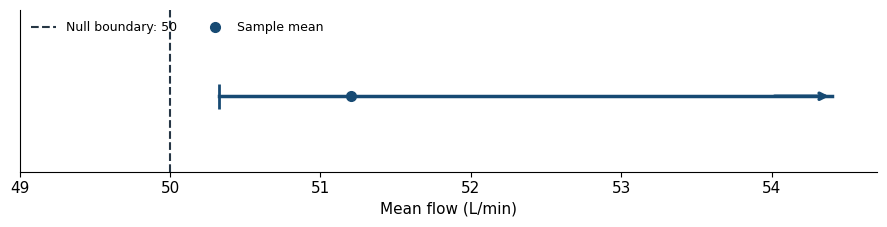

In [6]:
# Textbook z example: H0: mu = 15 versus H1: mu differs from 15.
# mu0_z, xbar_z, sigma, n_z = 15.0, 14.7, 0.9, 36
# alpha = 0.05
# se_z = sigma / np.sqrt(n_z)
# z_obs = (xbar_z - mu0_z) / se_z
# z_crit = norm.ppf(1 - alpha / 2)
# p_z = 2 * norm.sf(abs(z_obs))
# print(f"Known SD: z_obs={z_obs:.3f}, critical values=±{z_crit:.3f}, p={p_z:.4f}")
# print("Reject H0 at alpha=.05?", abs(z_obs) > z_crit)

# Pump example: H0: mu <= 50 versus H1: mu > 50, chosen in advance.
mu0_t, xbar_t, s, n_t = 50.0, 51.2, 2.0, 16
df = n_t - 1
se_t = s / np.sqrt(n_t)
t_obs = (xbar_t - mu0_t) / se_t
t_crit = t.ppf(1 - alpha, df=df)
p_t = t.sf(t_obs, df=df)
lower = xbar_t - t_crit * se_t
estimated_gain = xbar_t - mu0_t
print(f"Sample estimate: {xbar_t:.1f} - {mu0_t:.1f} = {estimated_gain:+.1f} L/min")
print("Question 1: Is there evidence that the population mean is above 50 L/min?")
print(f"t_obs={t_obs:.3f}, t_crit={t_crit:.3f}, one-sided p={p_t:.4f}")
print(f"Matching 95% lower bound for mu: [{lower:.2f}, infinity) L/min")
print("Evidence of any increase at alpha=.05?", p_t < alpha)

fig, ax = plt.subplots(figsize=(9, 2.4))
ax.axvline(50, color=INK, linestyle="--", label="Null boundary: 50")
ax.plot([lower, 54.4], [0, 0], color=BLUE, lw=2.5)
ax.annotate("", xy=(54.4, 0), xytext=(54.0, 0), arrowprops={"arrowstyle": "->", "color": BLUE, "lw": 2.5})
ax.plot(lower, 0, "|", color=BLUE, markersize=18, markeredgewidth=2)
ax.plot(xbar_t, 0, "o", color=BLUE, markersize=7, label="Sample mean")
ax.set(xlim=(49, 54.7), ylim=(-0.35, 0.4), xlabel="Mean flow (L/min)", yticks=[])
ax.legend(frameon=False, loc="upper left", ncol=3, fontsize=9)
fig.tight_layout()
plt.show()

## Code 3 — One-sample proportion z-test (large sample)

Among 200 independent 3D-print runs, 145 produce a warp-free part. The historical success probability is 0.75, and the prespecified concern is lower yield: H0: p >= 0.75 versus H1: p < 0.75. Under the null boundary p0 = 0.75, the expected counts are 150 warp-free and 50 warped parts, so a normal approximation is reasonable. Use p0 — not the observed proportion — in the null standard error. The orange area is the one-sided p-value.

Observed proportion: 0.725
Expected null counts: 150 warp-free, 50 warped
Null standard error: 0.0306
z_obs = -0.816; z_crit = -1.645
One-sided approximate p-value: 0.2071
Decision at alpha = 0.05: fail to reject H0


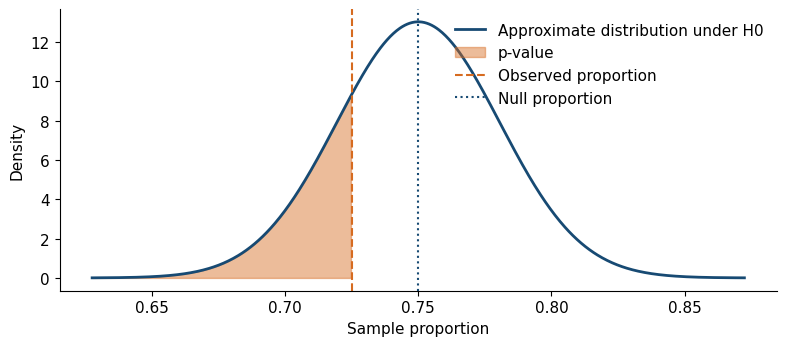

In [6]:
n_large, x_large, p0 = 200, 145, 0.75
alpha = 0.05
phat = x_large / n_large
se0 = np.sqrt(p0 * (1 - p0) / n_large)
z_obs = (phat - p0) / se0
z_crit = norm.ppf(alpha)  # Left-tailed rejection threshold
p_value = norm.cdf(z_obs)

print(f"Observed proportion: {phat:.3f}")
print(f"Expected null counts: {n_large*p0:.0f} warp-free, {n_large*(1-p0):.0f} warped")
print(f"Null standard error: {se0:.4f}")
print(f"z_obs = {z_obs:.3f}; z_crit = {z_crit:.3f}")
print(f"One-sided approximate p-value: {p_value:.4f}")
print("Decision at alpha = 0.05:", "reject H0" if p_value < alpha else "fail to reject H0")

grid = np.linspace(p0 - 4*se0, p0 + 4*se0, 800)
density = norm.pdf(grid, loc=p0, scale=se0)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(grid, density, color=BLUE, lw=2, label="Approximate distribution under H0")
ax.fill_between(grid, 0, density, where=grid <= phat, color=ORANGE, alpha=0.45, label="p-value")
ax.axvline(phat, color=ORANGE, linestyle="--", label="Observed proportion")
ax.axvline(p0, color=BLUE, linestyle=":", label="Null proportion")
ax.set(xlabel="Sample proportion", ylabel="Density")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

## Code 4 — When the normal approximation is doubtful: exact binomial test

Now consider only 20 independent 3D-print runs, of which 12 are warp-free. Under p0 = 0.75, the expected count of warped parts is only five. This is a poor setting for a routine normal approximation, so use the binomial distribution directly. The orange bars are the counts included in the lower-tail p-value. The two-sided Wilson interval describes plausible values of p, but it is not the exact dual of this one-sided test.

Observed success proportion: 0.60
Exact lower-tail p-value P(X <= 12 | p=0.75): 0.1018
Two-sided 95% Wilson interval: [0.387, 0.781]
Expected warped parts under H0: 5


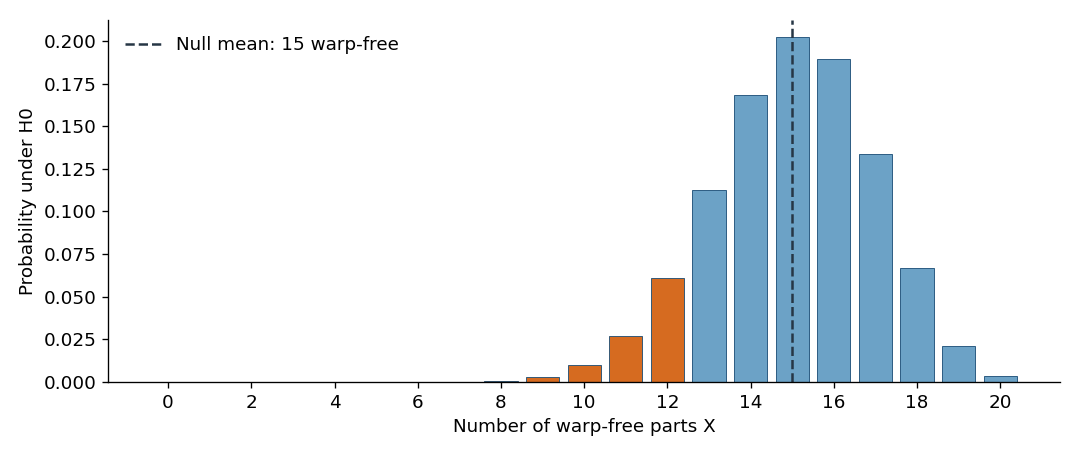

In [7]:
n, x_success, p0 = 20, 12, 0.75
result = binomtest(x_success, n=n, p=p0, alternative="less")
wilson_low, wilson_high = proportion_confint(x_success, n, alpha=0.05, method="wilson")
print(f"Observed success proportion: {x_success/n:.2f}")
print(f"Exact lower-tail p-value P(X <= {x_success} | p={p0:.2f}): {result.pvalue:.4f}")
print(f"Two-sided 95% Wilson interval: [{wilson_low:.3f}, {wilson_high:.3f}]")
print(f"Expected warped parts under H0: {n*(1-p0):.0f}")

k = np.arange(n + 1)
pmf = binom.pmf(k, n, p0)
colors = [ORANGE if value <= x_success else LIGHT_BLUE for value in k]
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(k, pmf, color=colors, edgecolor=BLUE, linewidth=0.5)
ax.axvline(n*p0, color=INK, linestyle="--", label="Null mean: 15 warp-free")
ax.set(xlabel="Number of warp-free parts X", ylabel="Probability under H0", xticks=np.arange(0, n+1, 2))
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

Closing distinction: the exact test asks whether the observed count is unusually low if p=0.75. The Wilson interval answers which success probabilities are plausible from this sample. Do not claim the two methods have identical decision boundaries.